# 06 · Incremental siting, and proving the greedy plan is good

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/james-kidd/pbn-gradio/blob/main/demos/notebooks/06_siting_and_lp.ipynb)

The SimCity question: given the roads and structures that already exist,
**where do we add next?**

The mechanic is that the network already built determines what is cheap
to build next — every placement rewrites the cost of the next one.

Then the part that makes it trustworthy: greedy is fast, explainable, and
unbounded in how bad it might be. Linear programming closes that gap with
a proof rather than an assurance.

In [1]:
# Bootstrap: clones what it needs in Colab, finds what exists locally.
import pathlib, subprocess, sys

REPO = "https://github.com/james-kidd/pbn-gradio.git"
BRANCH = "main"

def _demos_root():
    for base in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (base / "nbtools" / "bootstrap.py").exists():
            return base
    dest = (pathlib.Path("/content/pbn-gradio") if pathlib.Path("/content").is_dir()
            else pathlib.Path.cwd() / "pbn-gradio")
    if not (dest / "demos" / "nbtools").exists():
        subprocess.run(["git", "clone", "--depth", "1", "--quiet",
                        "--branch", BRANCH, REPO, str(dest)], check=True)
    return dest / "demos"

sys.path.insert(0, str(_demos_root()))
from nbtools.bootstrap import setup

tk = setup()                           # installs anything missing, first
from nbtools import scenes, display    # these need cv2/matplotlib, so: after

toolkit   /home/user/pbn-gradio  (found locally)
modules   geo, land_use, optimize, pipeline, segmenters, siting, topology
gradio    stubbed (UI layer not needed for these demos)


In [2]:
import numpy as np
from skimage import graph as skgraph

image = scenes.simple_farm()
working = tk.pipeline.load_and_resize(image, 800)
lab = tk.pipeline.preprocess_rgb(working)
MIN_AREA = int(working.shape[0] * working.shape[1] * 0.001)
ctx = tk.geo.GeoContext.from_scale(
    0.5, resize_scale=max(image.shape[:2]) / max(working.shape[:2]))

seg = tk.segmenters.segment(lab, "felzenszwalb", merge_threshold=8.0,
                            min_area=MIN_AREA, fill=True, n_segments=900,
                            sigma=2.0)   # see note below on thin features
labels = seg.labels

features = tk.land_use.extract_features(working, lab, labels)
tk.land_use.compute_topology(labels, features)
tk.land_use.classify_regions(features)
tk.land_use.compute_adjacency(labels, features)
tk.land_use.classify_regions(features)
print(f"{seg.describe()}  |  {ctx.describe()}")

felzenszwalb → merge<8 → drop<480px → fill-gaps (9 regions)  |  assumed scale · 0.5000 m/px · not georeferenced (coordinates are pixels)


## The cost surface

Land classes become dollars per metre of corridor. The ratios are what
drive routing and they are defensible: an existing right-of-way is an
order of magnitude cheaper to follow than mature canopy, and water needs a
structure.

Buildings are expensive but **finite** rather than infinite — a building
is not a wall of physics, and the estimate should say how expensive going
through it would be rather than pretending no route exists.

In [3]:
display.table(sorted(tk.siting.TRAVERSAL_COST.items(), key=lambda kv: kv[1]),
              ["class", "$ per metre"])

cost_surface = tk.siting.build_cost_surface(labels, features, ctx.m_per_px)
network, note = tk.siting.seed_network(labels, features)
print(f"network seed: {note}  ({int(network.sum())} px)")

| class | $ per metre |
|---|---|
| road | 12.0 |
| bare_soil | 45.0 |
| sparse_veg | 62.0 |
| stressed_veg | 62.0 |
| unclear | 90.0 |
| dense_veg | 145.0 |
| water | 420.0 |
| built | 900.0 |

network seed: detected road network  (6792 px)


### A gotcha worth keeping

That `sigma=2.0` in the segmentation cell is load-bearing. Felzenszwalb's
own default is **0.5**, and at that setting the road — twenty-two pixels
wide against a large green field — gets smoothed away before segmentation
even starts. No road means no network, and the whole analysis silently
falls back to "assume the grid is somewhere off-frame".

It is the concrete version of the warning that segmenters fight thin
features. The fallback reports itself rather than hiding, which is how it
is catchable at all, but the honest fix is to keep the feature.

## What would it cost to connect *anywhere*?

One least-cost-path solve from every network pixel at once gives the
cost-to-connect for every pixel on the frame. This is the single most
useful output here, and notably it needs no classification to read: dark
is cheap to reach, bright is expensive.

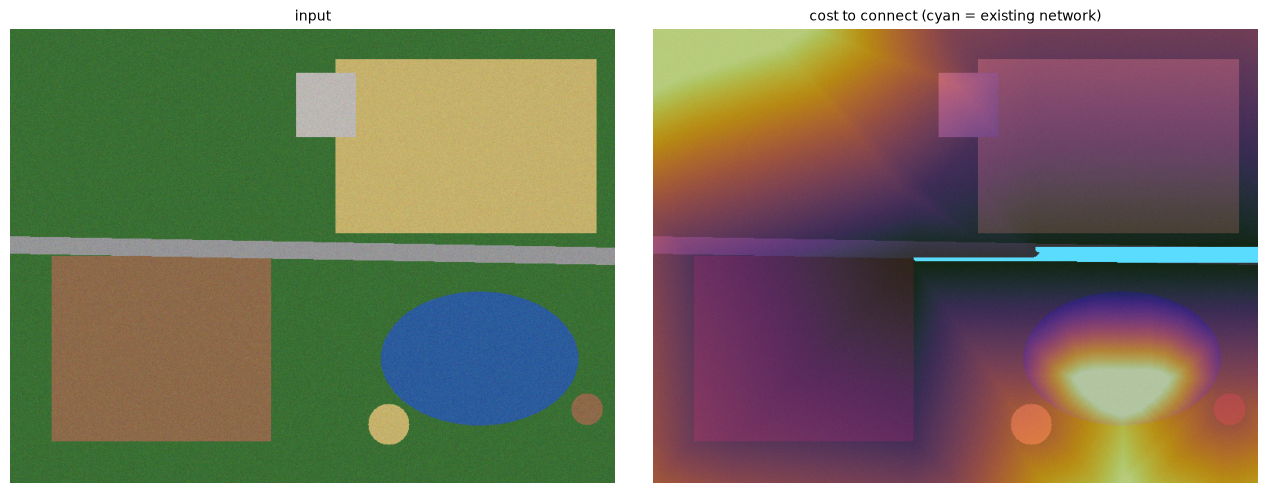

In [4]:
rows, cols = np.nonzero(network)
seeds = list(zip(rows.tolist(), cols.tolist()))
mcp = skgraph.MCP_Geometric(cost_surface)
cum, _ = mcp.find_costs(seeds)

display.grid(
    [working, tk.siting.render_connection_map(working, cum, network)],
    ["input", "cost to connect (cyan = existing network)"], columns=2, width=13)

## The loop

Place the best site, route its corridor, **add that corridor to the
network at reduced cost**, recompute, repeat. The surface has changed, so
the ranking has changed.

Each site also records what it *would* have cost built first. The gap
between the two is the measurable value of having sequenced the build
rather than costing each parcel independently.

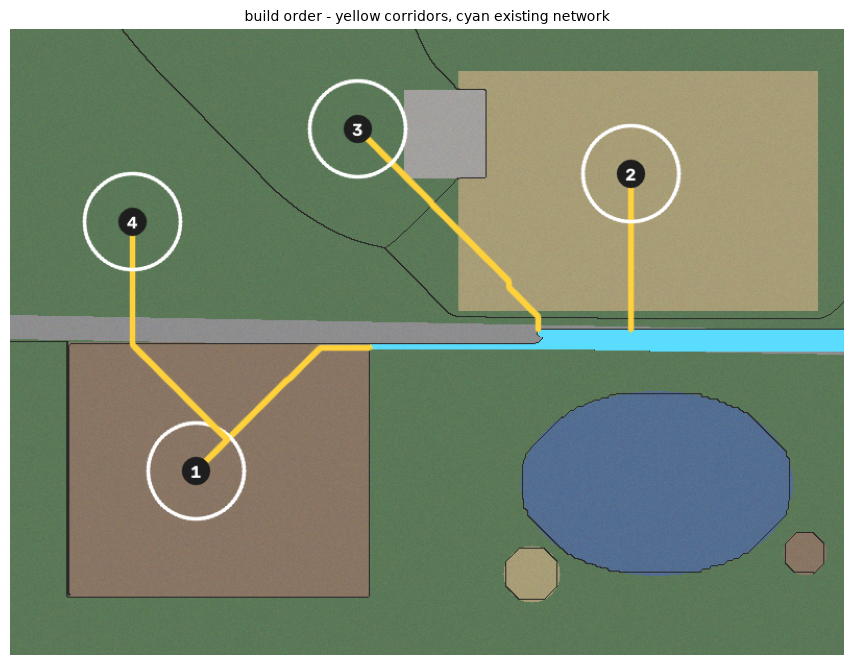

In [5]:
sites = tk.siting.candidate_sites(labels, features, ctx.m_per_px,
                                  min_area_ha=0.05, target_area_ha=2.0)
placed, grown = tk.siting.plan_build_order(
    cost_surface, network, sites, features, ctx.m_per_px,
    rounds=4, target_area_ha=2.0, connection_budget=40_000, corridor_cost=15.0)

display.show(tk.siting.render_plan(working, labels, grown, placed),
             "build order - yellow corridors, cyan existing network", width=9)

In [6]:
display.table(tk.siting.build_plan_table(placed), tk.siting.PLAN_TABLE_HEADERS)

| Build | Parcel | Class | Area (ha) | Holes | Work round | Corridor (m) | Connect cost | If built first | Saved by sequencing | Top reason |
|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 6 | Bare soil | 1.76 | — | — | 108 | $4,855 | $4,855 | — | cheap to connect |
| 2 | 1 | Stressed / senescent vegetation | 2.66 | — | — | 75 | $5,052 | $5,052 | — | usable size |
| 3 | 2 | Dense vegetation | 1.12 | — | — | 132 | $12,886 | $12,886 | — | cheap to connect |
| 4 | 3 | Dense vegetation | 2.16 | — | — | 123 | $11,415 | $13,649 | $2,234 | usable size |

In [7]:
display.markdown(tk.siting.build_siting_report(placed, len(sites), note, ctx.m_per_px))

### Build plan

**4 sites** selected from 6 candidate parcels · 7.70 ha · 439 m of new corridor · **$34,209** to connect

### What sequencing is worth

Costed independently — every parcel connecting to the network as it stands today — these same sites total **$36,443**. Built in the order above, where each corridor becomes a right-of-way the next build can tap, they total **$34,209**.

**Sequencing saves $2,234** (6%). That difference is the entire argument for planning the order rather than quoting each parcel on its own.

### Reading this honestly

- Network seed: **detected road network**
- Ground resolution: **0.500 m/px** — corridor lengths and therefore costs scale linearly with it
- **Routing is exact; the surface under it is not.** The cheapest corridor across a given cost surface is computed correctly and you can check it by eye. Where that surface comes from is our unvalidated classifier — which is the swappable part: feed in a published road centreline layer and the routing is production-grade unchanged.
- **No elevation data.** A single RGB frame cannot see slope, and slope dominates real trenching cost. A route that looks cheap here may cross a ravine.
- **No ownership, zoning, easements or grid capacity.** All four can veto a site this tool ranks first.

Use it to narrow many parcels to a few worth real diligence — not to choose one.

Look for a later corridor *joining* an earlier one rather than running its
own line to the road. That join is the saving, made visible.

## Naming what the loop approximates

Connecting a set of chosen sites to an existing network at minimum total
cost is the **Steiner tree problem** — NP-hard. The greedy loop is a
heuristic for it, and the standard 2-approximation (a minimum spanning
tree over the *metric closure* of the terminals) makes a yardstick.

It is a yardstick, not a target: it connects the same terminals as cheaply
as geometry allows while ignoring whether those parcels are worth building
on. Pricing that trade-off is the point.

In [8]:
steiner = tk.topology.steiner_benchmark(cost_surface, network,
                                        [s.point for s in placed])
achieved = sum(s.connection_cost for s in placed)
display.table(
    [["MST over metric closure", f"${steiner['mst_cost']:,.0f}"],
     ["This plan", f"${achieved:,.0f}"],
     ["Premium for desirability over cheapness",
      f"${achieved - steiner['mst_cost']:,.0f}"]],
    ["Measure", "Cost"])

| Measure | Cost |
|---|---|
| MST over metric closure | $34,615 |
| This plan | $34,209 |
| Premium for desirability over cheapness | $-406 |

## Proving the selection was good

Choosing parcels to maximise suitability under a budget is a **0-1
knapsack** — NP-hard. Relax the integrality and it becomes a linear
program, solvable exactly. Since every integral solution is also a
feasible fractional one, **the LP optimum upper-bounds the integer
optimum**.

So `greedy / LP` is not an estimate. It is a proof of how close greedy
came to the best achievable.

In [9]:
for s in sites:
    s.connection_cost = s.baseline_cost
tk.siting.score_sites(sites, features, 2.0, 40_000)

site_costs = [
    s.baseline_cost
    + tk.land_use.LAND_CLASSES[tk.land_use.CLASS_INDEX[s.class_key]].base_rate * s.area_ha
    for s in sites]
placed_ids = {id(s) for s in placed}
chosen = [i for i, s in enumerate(sites) if id(s) in placed_ids]
budget = sum(site_costs[i] for i in chosen)

cert = tk.optimize.budgeted_selection(
    [max(0.0, s.score) for s in sites], site_costs, budget, chosen)
display.markdown(
    tk.optimize.format_certificate(cert, [s.label for s in sites], chosen))

### Selection certificate (LP relaxation)

Choosing parcels to maximise suitability under a budget is a 0-1 knapsack — NP-hard. Its LP relaxation is solvable exactly, and since every integral solution is also a feasible fractional one, the LP optimum **upper-bounds** the best achievable. That turns the greedy plan's quality from an assertion into a proof.

| | |
|---|---:|
| LP upper bound | **17.41** |
| Greedy plan achieved | **16.36** |
| Certified optimality | **≥ 93.9%** |
| Value left on the table | at most 1.06 |
| Budget | $58,188 (spent $58,188) |

**Shadow price of the budget: 0.000164062 suitability per dollar.**

This is the dual variable on the budget constraint. By strong duality it is the exact marginal value of relaxing the budget at the optimum — so it answers *"is another dollar worth spending?"* without re-solving anything. Equivalently, by complementary slackness, it is the value-per-dollar threshold a parcel must clear to belong in the plan at all.

Reduced cost **vᵢ − λcᵢ** per parcel — positive clears the threshold, negative does not:

| Parcel | Reduced cost | LP | In plan |
|---|---:|---:|:--:|
| 6 | +3.817 | 1.00 | ✅ |
| 1 | +2.882 | 1.00 | ✅ |
| 9 | +0.647 | 1.00 | — |
| 2 | +0.519 | 1.00 | ✅ |
| 5 | +0.000 | 0.42 | — |
| 3 | -0.409 | 0.00 | ✅ |

*Scope: this certifies **selection** under independent costs. It does not certify **routing** — shared corridors couple the costs and break the knapsack structure. Routing is benchmarked separately against the MST over the metric closure.*

### Reading the dual

The budget constraint carries one dual variable λ. By strong duality it is
the **exact** marginal suitability bought by one more dollar — so it
answers *"should I raise the budget?"* without re-solving anything.

Complementary slackness then makes the reduced cost `vᵢ − λcᵢ`
diagnostic: λ is precisely the value-per-dollar threshold a parcel must
clear. A parcel in the plan with a **negative** reduced cost is one greedy
should not have taken; a parcel outside it with a **positive** one is a
parcel greedy should have taken.

That is not a vague "greedy could be better" — it names the specific swap.

## Scope, kept honest

- The LP certifies **selection** under independent costs. It does not
  certify **routing** — shared corridors couple the costs and break the
  knapsack structure. Routing has its own MST benchmark above. Two
  guarantees over two separable decisions.
- **Routing is exact; the surface under it is not.** The cheapest corridor
  across a given cost surface is computed correctly and you can check it by
  eye. Where that surface comes from is the unvalidated classifier — and
  that is the swappable part. Feed in a published road centreline layer and
  the routing is production-grade unchanged.
- **No elevation.** A single RGB frame cannot see slope, and slope
  dominates real trenching cost.

Use this to narrow many parcels to a few worth real diligence, not to
choose one.